# 01 - EDA: Home Credit Default Risk
Tujuan: memahami data `application_train`, proporsi gagal bayar, missing value, dan faktor yang tampak berkaitan dengan risiko.
Data dibaca langsung dari PostgreSQL (schema `raw`).

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# cari folder utama project (yang berisi docker-compose.yml) supaya `src` bisa di-import
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docker-compose.yml").exists())
sys.path.append(str(ROOT))

from src.db import get_engine

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
engine = get_engine()

## 1. Cek jumlah baris semua tabel

In [2]:
tables = ["application_train", "application_test", "bureau", "bureau_balance",
          "previous_application", "pos_cash_balance", "installments_payments",
          "credit_card_balance"]
counts = {t: int(pd.read_sql(f"SELECT COUNT(*) AS n FROM raw.{t}", engine)["n"][0]) for t in tables}
pd.Series(counts, name="jumlah_baris").map("{:,}".format)

application_train           307,511
application_test             48,744
bureau                    1,716,428
bureau_balance           27,299,925
previous_application      1,670,214
pos_cash_balance         10,001,358
installments_payments    13,605,401
credit_card_balance       3,840,312
Name: jumlah_baris, dtype: str

## 2. Proporsi gagal bayar (TARGET)
`1` = nasabah mengalami kesulitan bayar, `0` = lainnya. Angka ini menentukan seberapa tidak seimbang datanya.

In [3]:
target = pd.read_sql("""
    SELECT target,
           COUNT(*) AS jumlah,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS persen
    FROM raw.application_train
    GROUP BY target
    ORDER BY target
""", engine)
target

,target,jumlah,persen
0,0,282686,91.93
1,1,24825,8.07


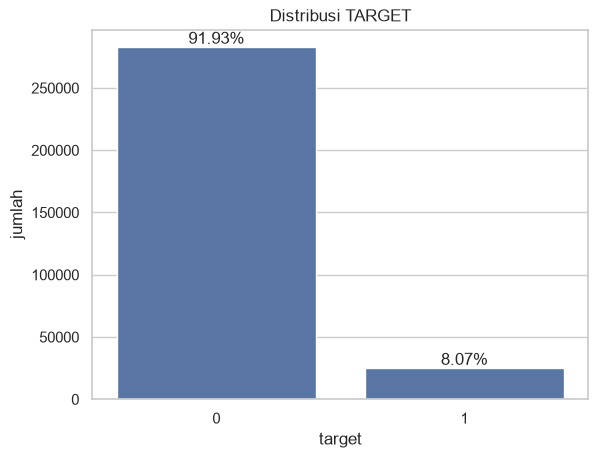

In [4]:
ax = sns.barplot(data=target, x="target", y="jumlah")
ax.set_title("Distribusi TARGET")
for i, row in target.iterrows():
    ax.text(i, row["jumlah"], f"{row['persen']}%", ha="center", va="bottom")
plt.show()

## 3. Muat application_train ke pandas
Tabel ini cukup kecil (sekitar 307 ribu baris), jadi aman dimuat penuh.

In [5]:
app = pd.read_sql("SELECT * FROM raw.application_train", engine)
print(app.shape)
app.head()

(307511, 122)


,sk_id_curr,target,name_contract_type,code_gender,flag_own_car,flag_own_realty,cnt_children,amt_income_total,amt_credit,amt_annuity,amt_goods_price,name_type_suite,name_income_type,name_education_type,name_family_status,name_housing_type,region_population_relative,days_birth,days_employed,days_registration,days_id_publish,own_car_age,flag_mobil,flag_emp_phone,flag_work_phone,...,flag_document_3,flag_document_4,flag_document_5,flag_document_6,flag_document_7,flag_document_8,flag_document_9,flag_document_10,flag_document_11,flag_document_12,flag_document_13,flag_document_14,flag_document_15,flag_document_16,flag_document_17,flag_document_18,flag_document_19,flag_document_20,flag_document_21,amt_req_credit_bureau_hour,amt_req_credit_bureau_day,amt_req_credit_bureau_week,amt_req_credit_bureau_mon,amt_req_credit_bureau_qrt,amt_req_credit_bureau_year
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.028663,-19932,-3038,-4311.0,-3458,NaN,1,1,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 4. Missing value

In [6]:
missing = (app.isna().mean() * 100).sort_values(ascending=False)
print(f"Kolom dengan missing value: {(missing > 0).sum()} dari {app.shape[1]}")
missing.head(20).round(1)

Kolom dengan missing value: 67 dari 122


commonarea_avg              69.9
commonarea_mode             69.9
commonarea_medi             69.9
nonlivingapartments_medi    69.4
nonlivingapartments_mode    69.4
nonlivingapartments_avg     69.4
fondkapremont_mode          68.4
livingapartments_avg        68.4
livingapartments_medi       68.4
livingapartments_mode       68.4
floorsmin_mode              67.8
floorsmin_avg               67.8
floorsmin_medi              67.8
years_build_avg             66.5
years_build_mode            66.5
years_build_medi            66.5
own_car_age                 66.0
landarea_medi               59.4
landarea_avg                59.4
landarea_mode               59.4
dtype: float64

## 5. Tingkat gagal bayar per kategori

In [7]:
for col in ["name_contract_type", "code_gender", "name_education_type", "name_income_type"]:
    rate = app.groupby(col)["target"].agg(jumlah="size", default_rate="mean")
    rate["default_rate"] = (rate["default_rate"] * 100).round(2)
    print(col)
    display(rate.sort_values("default_rate", ascending=False))

name_contract_type


,jumlah,default_rate
name_contract_type,,
Cash loans,278232,8.35
Revolving loans,29279,5.48


code_gender


,jumlah,default_rate
code_gender,,
M,105059,10.14
F,202448,7.00
XNA,4,0.00


name_education_type


,jumlah,default_rate
name_education_type,,
Lower secondary,3816,10.93
Secondary / secondary special,218391,8.94
Incomplete higher,10277,8.48
Higher education,74863,5.36
Academic degree,164,1.83


name_income_type


,jumlah,default_rate
name_income_type,,
Maternity leave,5,40.00
Unemployed,22,36.36
Working,158774,9.59
Commercial associate,71617,7.48
State servant,21703,5.75
Pensioner,55362,5.39
Businessman,10,0.00
Student,18,0.00


## 6. Fitur numerik penting
`days_birth` dan `days_employed` bernilai negatif (hari sebelum tanggal aplikasi). Khusus `days_employed`, nilai 365243 adalah placeholder anomali, bukan lama kerja sungguhan.

In [8]:
app["umur_tahun"] = -app["days_birth"] / 365
anomali = app["days_employed"].eq(365243)
print(f"Baris dengan days_employed = 365243: {anomali.mean() * 100:.1f}%")

app["lama_kerja_tahun"] = (-app["days_employed"]).where(~anomali) / 365
app[["umur_tahun", "lama_kerja_tahun", "amt_income_total", "amt_credit", "amt_annuity"]].describe().round(1)

Baris dengan days_employed = 365243: 18.0%


,umur_tahun,lama_kerja_tahun,amt_income_total,amt_credit,amt_annuity
count,307511.0,252137.0,307511.0,307511.0,307499.0
mean,43.9,6.5,168797.9,599026.0,27108.6
std,12.0,6.4,237123.1,402490.8,14493.7
min,20.5,0.0,25650.0,45000.0,1615.5
25%,34.0,2.1,112500.0,270000.0,16524.0
50%,43.2,4.5,147150.0,513531.0,24903.0
75%,53.9,8.7,202500.0,808650.0,34596.0
max,69.1,49.1,117000000.0,4050000.0,258025.5


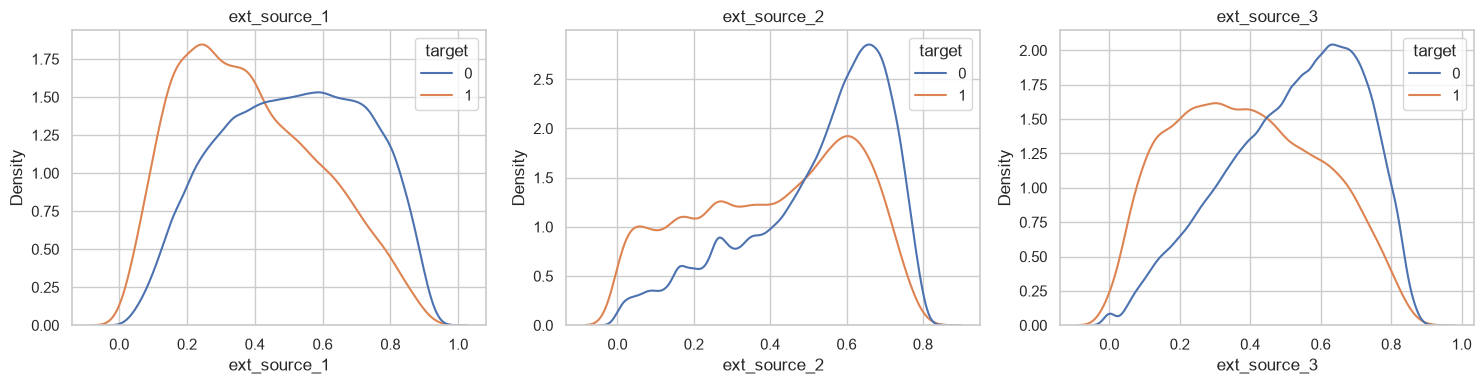

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["ext_source_1", "ext_source_2", "ext_source_3"]):
    sns.kdeplot(data=app, x=col, hue="target", common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 7. Korelasi fitur numerik dengan TARGET
Ini hanya gambaran awal korelasi linear. Pengaruh sebenarnya akan kita lihat nanti dengan model dan SHAP.

In [10]:
corr = (app.select_dtypes("number").corr()["target"]
        .drop("target")
        .sort_values(key=abs, ascending=False))
corr.head(15).round(3)

ext_source_3                  -0.179
ext_source_2                  -0.160
ext_source_1                  -0.155
umur_tahun                    -0.078
days_birth                     0.078
lama_kerja_tahun              -0.075
region_rating_client_w_city    0.061
region_rating_client           0.059
days_last_phone_change         0.055
days_id_publish                0.051
reg_city_not_work_city         0.051
flag_emp_phone                 0.046
days_employed                 -0.045
reg_city_not_live_city         0.044
flag_document_3                0.044
Name: target, dtype: float64

## Catatan temuan
- **Proporsi gagal bayar:** 8,07% (24.825 dari 307.511 nasabah), rasio sekitar 11,4 : 1.
  Data tidak seimbang, jadi akurasi tidak dipakai. Metrik utama: ROC-AUC dan PR-AUC,
  dengan split stratified dan class weight.
- **Missing value:** 67 dari 122 kolom punya nilai kosong. Terbanyak (59-70%) ada di
  fitur bangunan tempat tinggal (`commonarea`, `livingapartments`, `years_build`, dst.)
  yang tiap fiturnya muncul dalam versi `_avg`, `_mode`, `_medi`.
- **Kategori dengan default rate tertinggi:** pendidikan rendah (Lower secondary 10,93%
  vs Higher education 5,36%), laki-laki (10,14% vs 7,00%), Cash loans (8,35% vs
  Revolving loans 5,48%), dan tipe penghasilan Working (9,59%). Kategori kecil
  (Maternity leave n=5, Unemployed n=22) terlihat ekstrem tetapi sampelnya terlalu sedikit.
- **Fitur yang paling berkaitan dengan TARGET:** `ext_source_3` (-0,179), `ext_source_2`
  (-0,160), `ext_source_1` (-0,155), lalu umur (-0,078) dan lama kerja (-0,075).
  Ini korelasi linear lemah, bukan sebab-akibat.
- **Anomali data:** `days_employed = 365243` adalah placeholder, bukan lama kerja asli
  (XX% baris). Sudah dibersihkan menjadi `lama_kerja_tahun`.
- **Rencana lanjutan:** agregasi 6 tabel lain (bureau, previous_application, dst.) ke
  level nasabah, lalu bandingkan beberapa model dan jelaskan dengan SHAP.